In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Usted dirige, para una empresa instaladora, la ejecución de un contrato con una administración pública (precio 1180 k€, IVA excluido, plazo 22 semanas, penalidades por demora las de la ley). El cuadro de prelaciones, las duraciones (semanas) y los operarios de cada actividad se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 7       , 4        ),
    ('B'     , '---'      , 8       , 2        ),
    ('C'     , 'B'        , 4       , 4        ),
    ('D'     , 'A'        , 1       , 2        ),
    ('E'     , 'C'        , 1       , 4        ),
    ('F'     , 'B'        , 4       , 4        ),
    ('G'     , 'C'        , 4       , 1        ),
    ('H'     , 'D,F,G'    , 6       , 1        ),
    ('I'     , 'E,F,G'    , 3       , 3        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,7,4
B,---,8,2
C,B,4,4
D,A,1,2
E,C,1,4
F,B,4,4
G,C,4,1
H,"D,F,G",6,1
I,"E,F,G",3,3


> **De: Director de operaciones**
> Necesito los 2 operarios de la actividad B durante 2 semanas, desde que empiece, para el proyecto del cliente grande: allí nos ahorramos 14.9 k€ de penalización. B se para esas semanas y sigue después. Si tu cliente pregunta, dile que es un retraso del proveedor de material; no quiero que sepa que hemos movido gente.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C1 — Afirmación falsa.** Comunicar como cierto un dato que quien lo comunica sabe que no lo es (un porcentaje de avance, una causa, una oferta que no existe). *(cf. Código Ético del PMI, estándar obligatorio 5.3.1; ICB4, Personas 2 «integridad personal y fiabilidad».)*
- **C5 — Beneficio propio a costa de otro.** Obtener una ventaja (dinero, plazo, reputación) trasladando el coste a otra parte que no lo ha aceptado. *(cf. Código Ético del PMI, 5.3.2 y 3.3.2.)*
- **Norma — penalidad diaria por demora en la ejecución de un contrato del sector público, salvo que el pliego fije otra: 0,60 € por cada 1 000 € del precio del contrato (IVA excluido) por día** *(Ley 9/2017 de Contratos del Sector Público, art. 193.3.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule el calendario y la holgura total de B, el retraso del proyecto si B se para 2 semanas y la penalidad legal que supondría (días naturales).  "
pregunta_2 = "2. (A) Compare la penalidad con lo que se ahorra el otro proyecto. ¿Qué conviene a la empresa en conjunto? ¿Cuántas semanas podría cederse B sin retrasar el proyecto?  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿qué incumple decir al cliente que el retraso es «del proveedor de material»? ¿Y desviar los operarios sin decírselo? ¿Depende la respuesta de qué proyecto convenga más a la empresa?  "
pregunta_4 = "4. (C) ¿Qué propone al director de operaciones y qué comunica al cliente? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule el calendario y la holgura total de B, el retraso del proyecto si B se para 2 semanas y la penalidad legal que supondría (días naturales).  

2. (A) Compare la penalidad con lo que se ahorra el otro proyecto. ¿Qué conviene a la empresa en conjunto? ¿Cuántas semanas podría cederse B sin retrasar el proyecto?  

3. (B) Según los criterios de referencia, ¿qué incumple decir al cliente que el retraso es «del proveedor de material»? ¿Y desviar los operarios sin decírselo? ¿Depende la respuesta de qué proyecto convenga más a la empresa?  

4. (C) ¿Qué propone al director de operaciones y qué comunica al cliente? Aplique la rúbrica.  

# Resolución

In [6]:
X, semanas_parada, precio_contrato, penalidad_por_mil_y_dia, ahorro_otro_proyecto = 'B', 2, 1180, 0.6, 14.9
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

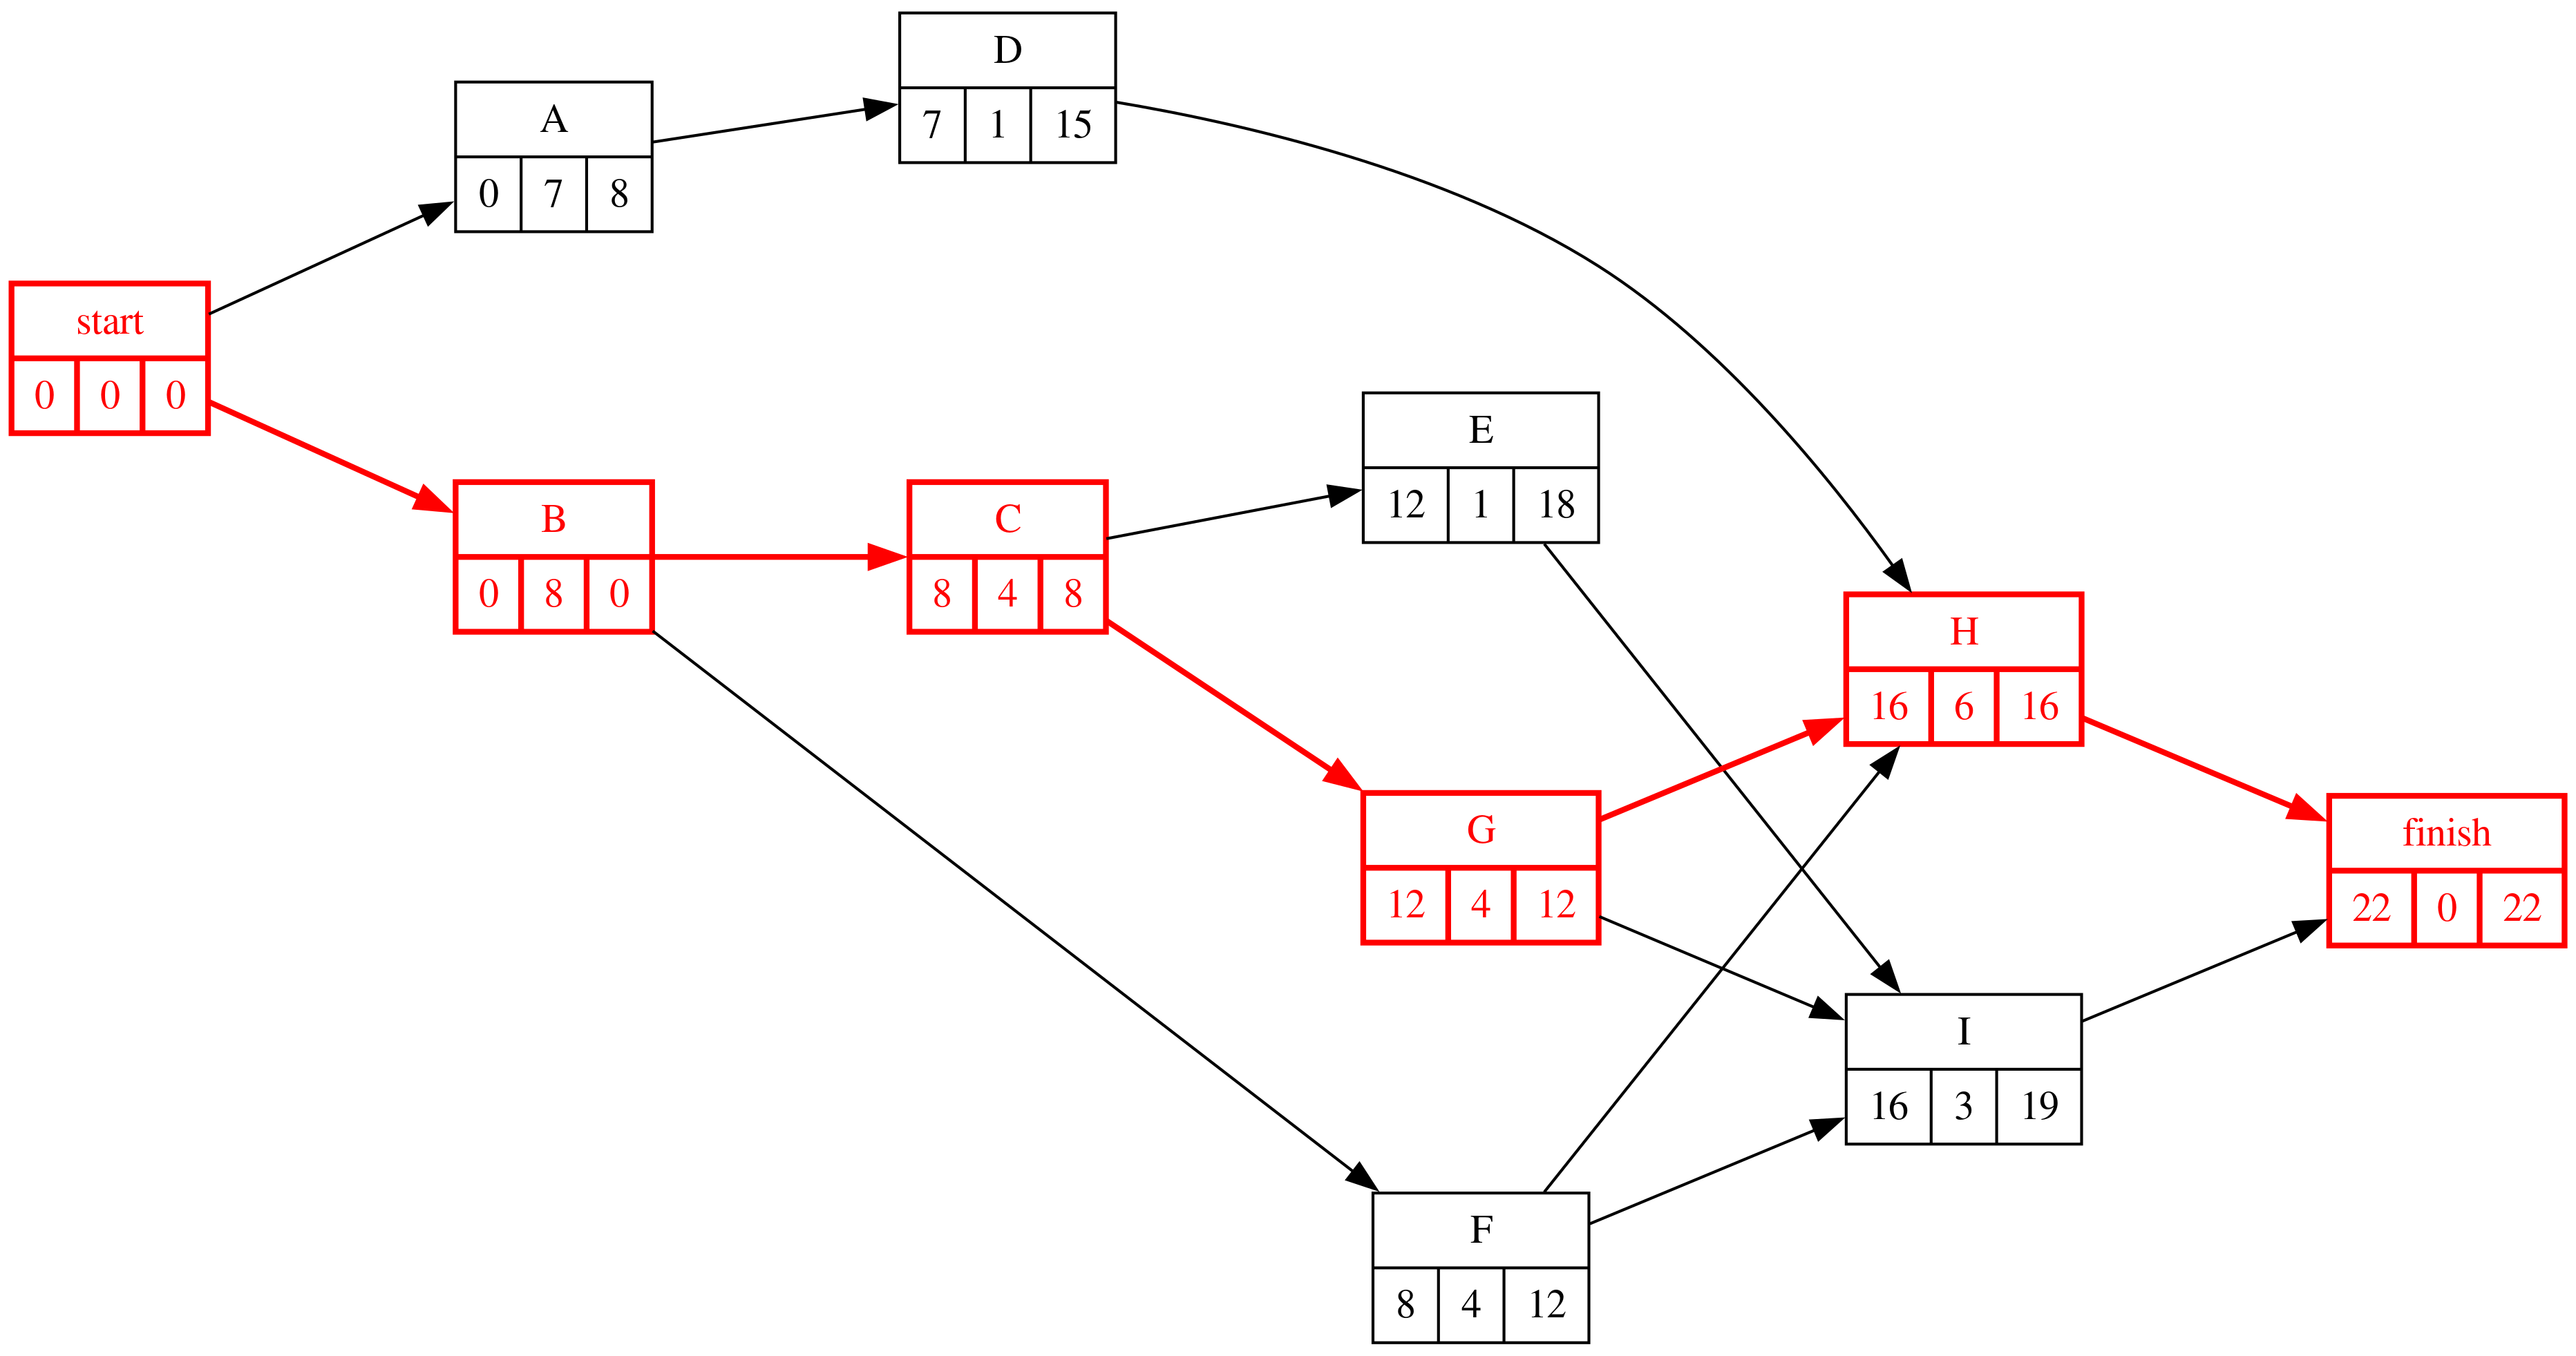

In [8]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+8 = 8$ &nbsp; (B)
- $T_{D} = 0+7 = 7$ &nbsp; (A)
- $T_{F} = 0+8 = 8$ &nbsp; (B)
- $T_{E} = 8+4 = 12$ &nbsp; (C)
- $T_{G} = 8+4 = 12$ &nbsp; (C)
- $T_{H} = \max\{7+1,\ 8+4,\ 12+4\} = 16$ &nbsp; (D, F, G)
- $T_{I} = \max\{8+4,\ 12+1,\ 12+4\} = 16$ &nbsp; (F, E, G)
- $T_{\mathrm{Fin}} = \max\{16+6,\ 16+3\} = 22$ &nbsp; (H, I)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 22$
- $T_{I}^{*} = 22-3 = 19$ &nbsp; (Fin)
- $T_{H}^{*} = 22-6 = 16$ &nbsp; (Fin)
- $T_{G}^{*} = \min\{16-4,\ 19-4\} = 12$ &nbsp; (H, I)
- $T_{E}^{*} = 19-1 = 18$ &nbsp; (I)
- $T_{F}^{*} = \min\{16-4,\ 19-4\} = 12$ &nbsp; (H, I)
- $T_{D}^{*} = 16-1 = 15$ &nbsp; (H)
- $T_{C}^{*} = \min\{18-4,\ 12-4\} = 8$ &nbsp; (E, G)
- $T_{B}^{*} = \min\{8-8,\ 12-8\} = 0$ &nbsp; (C, F)
- $T_{A}^{*} = 15-7 = 8$ &nbsp; (D)
- $T_{\mathrm{Inicio}}^{*} = \min\{8-0,\ 0-0\} = 0$ &nbsp; (A, B)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule el calendario y la holgura total de B, el retraso del proyecto si B se para 2 semanas y la penalidad legal que supondría (días naturales).  

In [10]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,8,7,15,0,0,8,7
B,0,0,8,8,0,0,0,8
C,8,8,12,12,0,0,0,4
D,7,15,8,16,8,0,8,1
E,12,18,13,19,3,3,6,1
F,8,12,12,16,0,0,4,4
G,12,12,16,16,0,0,0,4
H,16,16,22,22,0,0,0,6
I,16,19,19,22,3,0,3,3


In [11]:
H = int(calendario.loc[X, 'H_total'])
d = datos_proyecto['duration'].copy(); d[X] = d[X] + semanas_parada
duracion_con_parada = int(proyecto.duration(d))
retraso = duracion_con_parada - duracion
penalidad = penalidad_por_mil_y_dia * precio_contrato / 1000 * 7 * retraso
Markdown(f'''{X} tiene holgura total {H}; parada {semanas_parada} semanas, el proyecto pasa de {duracion} a **{duracion_con_parada}** semanas (retraso {retraso} = máx(0, {semanas_parada} − {H})). Penalidad: {penalidad_por_mil_y_dia} € por cada 1 000 € × {precio_contrato} k€ = {penalidad_por_mil_y_dia * precio_contrato / 1000:.2f} k€ por día × 7 × {retraso} días = **{penalidad:.1f} k€**.''')

B tiene holgura total 0; parada 2 semanas, el proyecto pasa de 22 a **24** semanas (retraso 2 = máx(0, 2 − 0)). Penalidad: 0.6 € por cada 1 000 € × 1180 k€ = 0.71 k€ por día × 7 × 2 días = **9.9 k€**.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. (A) Compare la penalidad con lo que se ahorra el otro proyecto. ¿Qué conviene a la empresa en conjunto? ¿Cuántas semanas podría cederse B sin retrasar el proyecto?  

In [13]:
neto_empresa = ahorro_otro_proyecto - penalidad
Markdown(f'''El otro proyecto ahorra {ahorro_otro_proyecto} k€ y este pierde {penalidad:.1f} k€: neto para la empresa **{neto_empresa:+.1f} k€** ({'conviene' if neto_empresa > 0 else 'no conviene'} ceder, en cifras). Sin retrasar el proyecto, B podría cederse como mucho **{H}** semana(s), las de su holgura total.''')

El otro proyecto ahorra 14.9 k€ y este pierde 9.9 k€: neto para la empresa **+5.0 k€** (conviene ceder, en cifras). Sin retrasar el proyecto, B podría cederse como mucho **0** semana(s), las de su holgura total.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿qué incumple decir al cliente que el retraso es «del proveedor de material»? ¿Y desviar los operarios sin decírselo? ¿Depende la respuesta de qué proyecto convenga más a la empresa?  

**C1.** Decir al cliente que el retraso lo causa el proveedor de material, sabiendo que lo causa una decisión propia, es una afirmación falsa; además, en un contrato público, la causa del retraso determina si procede la penalidad o una prórroga (la causa imputable al contratista no da derecho a prórroga), de modo que la mentira tiene consecuencias jurídicas. **C5.** Desviar los operarios sin decirlo traslada al cliente un coste (el retraso) para beneficio de otro cliente de la empresa, sin su conocimiento. La respuesta de B **no depende** del apartado 2: que a la empresa le convenga ceder dice qué debería negociar con el cliente, no que pueda ocultárselo ni mentirle sobre la causa. Lo que sí depende de la cifra es la decisión de negocio: ceder hasta 0 semanas es gratis en plazo; más, cuesta la penalidad.

In [15]:
preguntas_test = [
    ('Atribuir al proveedor un retraso causado por una decisión propia es…', ['C1, afirmación falsa', 'C2, verdad a medias', 'C4, retención de información', 'legítimo si la empresa gana en conjunto'],
     'Se afirma una causa que se sabe falsa; además condiciona la penalidad y la prórroga.'),
    ('La penalidad diaria por demora de la LCSP (art. 193.3), salvo que el pliego fije otra, es…', ['0,60 € por cada 1 000 € del precio', '1 % del precio', '0,60 % del precio', '60 € por día'],
     'Por cada 1 000 € de precio sin IVA y por día natural de demora.'),
    ('Una actividad puede cederse sin retrasar el proyecto durante…', ['su holgura total', 'su duración', 'su holgura independiente más su duración', 'ninguna semana si es crítica o no'],
     'Hasta la holgura total el proyecto no se retrasa; sus sucesoras sí pueden verse afectadas.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — recurso desviado')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — recurso desviado

::Ética 19 — recurso desviado P1::Atribuir al proveedor un retraso causado por una decisión propia es… {=C1, afirmación falsa ~C2, verdad a medias ~C4, retención de información ~legítimo si la empresa gana en conjunto ####Se afirma una causa que se sabe falsa; además condiciona la penalidad y la prórroga.}

::Ética 19 — recurso desviado P2::La penalidad diaria por demora de la LCSP (art. 193.3), salvo que el pliego fije otra, es… {~60 € por día =0,60 € por cada 1 000 € del precio ~0,60 % del precio ~1 % del precio ####Por cada 1 000 € de precio sin IVA y por día natural de demora.}

::Ética 19 — recurso desviado P3::Una actividad puede cederse sin retrasar el proyecto durante… {~ninguna semana si es crítica o no =su holgura total ~su duración ~su holgura independiente más su duración ####Hasta la holgura total el proyecto no se retrasa; sus sucesoras sí pueden verse afectadas.}



## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de operaciones y qué comunica al cliente? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de operaciones: la tabla de opciones (ceder 0 semanas gratis; ceder 2 con 9.9 k€ de penalidad y un retraso de 2 semanas que hay que comunicar; reforzar B con subcontrata) y la condición de que el cliente conozca la causa real. Al cliente, si se cede más de la holgura: aviso por escrito del retraso previsto, su causa y, si se quiere, una propuesta (compensación, recuperación en otra actividad). Prueba de publicidad: la versión «del proveedor» no resiste una llamada del cliente al proveedor.